In [1]:
# Assignment 3: Data Cleaning and Preprocessing Techniques

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(
    r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-3-Data-Cleaning-and-Preprocessing\automobile.csv"
)

original_shape = df.shape

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (205, 26)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of rows: 205
Number of columns: 26

Column Names:
['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    str    
 2   make               205 non-null    str    
 3   fuel-type          205 non-null    str    
 4   aspiration         205 non-null    str    
 5   num-of-doors       205 non-null    str    
 6   body-style         205 non-null    str    
 7   drive-wheels       205 non-null

In [4]:
df.describe()

,symboling,wheel-base,length,width,height,curb-weight,engine-size,compression-ratio,city-mpg,highway-mpg
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,10.142537,25.219512,30.751220
std,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,3.972040,6.542142,6.886443
min,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,7.000000,13.000000,16.000000
25%,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,8.600000,19.000000,25.000000
50%,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,9.000000,24.000000,30.000000
75%,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,9.400000,30.000000,34.000000
max,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,23.000000,49.000000,54.000000


In [5]:
marker_counts = df.astype(str).eq("?").sum()

print("Columns containing '?' as a missing value marker:")
print(marker_counts[marker_counts > 0])

Columns containing '?' as a missing value marker:
normalized-losses    41
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
price                 4
dtype: int64


In [6]:
df = df.replace("?", np.nan)

print("Missing values after replacing '?' with NaN:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values after replacing '?' with NaN:
normalized-losses    41
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
price                 4
dtype: int64


In [7]:
numeric_columns = [
    "normalized-losses",
    "bore",
    "stroke",
    "horsepower",
    "peak-rpm",
    "price"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column])

print(df[numeric_columns].dtypes)

normalized-losses    float64
bore                 float64
stroke               float64
horsepower           float64
peak-rpm             float64
price                float64
dtype: object


In [8]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percent": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary[missing_summary["Missing Count"] > 0]

,Missing Count,Missing Percent
normalized-losses,41,20.00
num-of-doors,2,0.98
bore,4,1.95
stroke,4,1.95
horsepower,2,0.98
peak-rpm,2,0.98
price,4,1.95


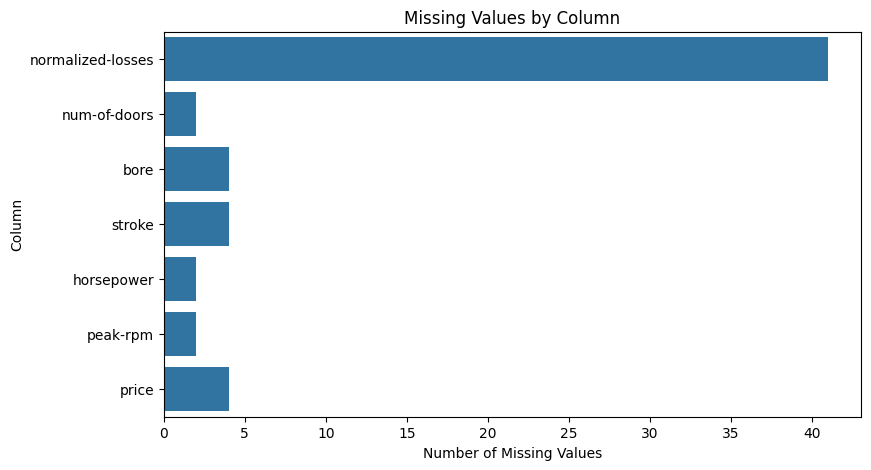

In [9]:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=missing_counts.values,
    y=missing_counts.index
)

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.show()

In [10]:
# Price is the target column, so records without a price are removed
df = df.dropna(subset=["price"])

print("Rows remaining:", df.shape[0])

Rows remaining: 201


In [11]:
median_fill_columns = [
    "normalized-losses",
    "bore",
    "stroke",
    "horsepower",
    "peak-rpm"
]

for column in median_fill_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing values in numeric columns:")
print(df[median_fill_columns].isnull().sum())

Missing values in numeric columns:
normalized-losses    0
bore                 0
stroke               0
horsepower           0
peak-rpm             0
dtype: int64


In [12]:
df["num-of-doors"] = df["num-of-doors"].fillna(
    df["num-of-doors"].mode()[0]
)

print("Total missing values remaining:", df.isnull().sum().sum())

Total missing values remaining: 0


In [13]:
word_to_number = {
    "two": 2,
    "three": 3,
    "four": 4,
    "five": 5,
    "six": 6,
    "eight": 8,
    "twelve": 12
}

df["num-of-doors"] = df["num-of-doors"].map(word_to_number)
df["num-of-cylinders"] = df["num-of-cylinders"].map(word_to_number)

df[["num-of-doors", "num-of-cylinders"]].head()

,num-of-doors,num-of-cylinders
0,2,4
1,2,4
2,2,6
3,4,4
4,4,5


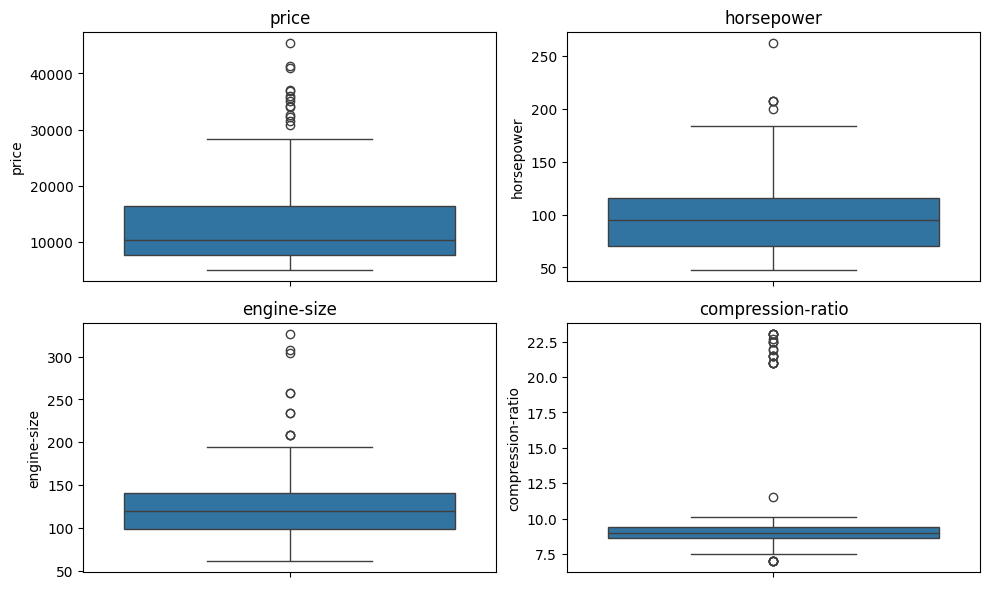

In [14]:
outlier_columns = [
    "price",
    "horsepower",
    "engine-size",
    "compression-ratio"
]

plt.figure(figsize=(10, 6))

for i, column in enumerate(outlier_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [15]:
def count_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    return ((series < lower_limit) | (series > upper_limit)).sum()


print("Outliers detected using the IQR method:")

for column in outlier_columns:
    print(column, ":", count_outliers(df[column]))

Outliers detected using the IQR method:
price : 14
horsepower : 5
engine-size : 10
compression-ratio : 27


In [16]:
def cap_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    return series.clip(lower_limit, upper_limit)


for column in outlier_columns:
    df[column] = cap_outliers(df[column])

print("Outliers remaining after capping:")

for column in outlier_columns:
    print(column, ":", count_outliers(df[column]))

Outliers remaining after capping:
price : 0
horsepower : 0
engine-size : 0
compression-ratio : 0


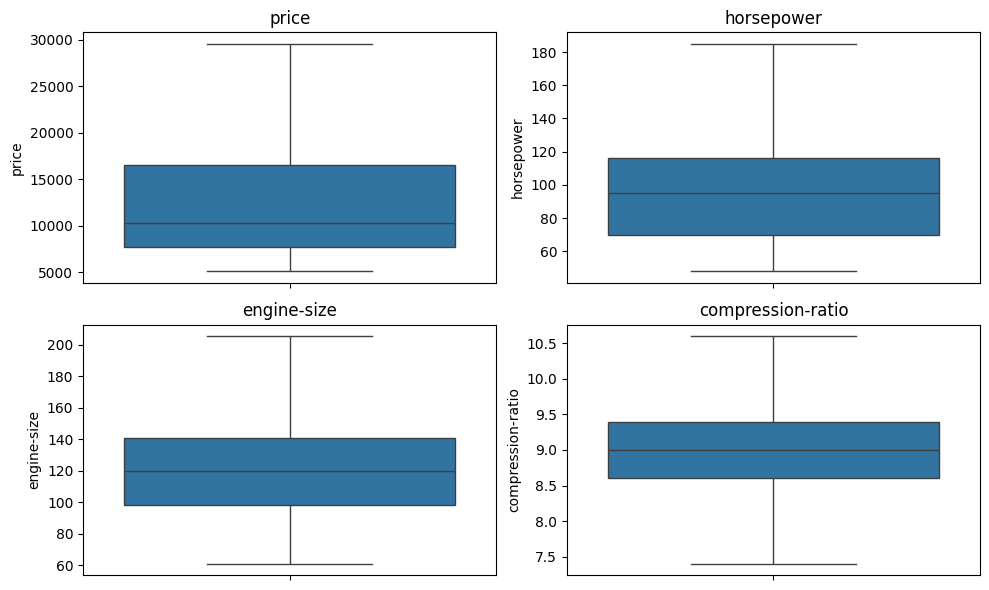

In [17]:
plt.figure(figsize=(10, 6))

for i, column in enumerate(outlier_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [18]:
# Capping can make near identical records exactly equal
print("Number of duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 1
Shape after removing duplicates: (200, 26)


In [19]:
categorical_columns = [
    "make",
    "fuel-type",
    "aspiration",
    "body-style",
    "drive-wheels",
    "engine-location",
    "engine-type",
    "fuel-system"
]

for column in categorical_columns:
    print(column, ":", df[column].nunique(), "unique values")

make : 22 unique values
fuel-type : 2 unique values
aspiration : 2 unique values
body-style : 5 unique values
drive-wheels : 3 unique values
engine-location : 2 unique values
engine-type : 6 unique values
fuel-system : 8 unique values


In [20]:
binary_columns = [
    "fuel-type",
    "aspiration",
    "engine-location"
]

encoder = LabelEncoder()

for column in binary_columns:
    df[column] = encoder.fit_transform(df[column])

df[binary_columns].head()

,fuel-type,aspiration,engine-location
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


In [21]:
nominal_columns = [
    "make",
    "body-style",
    "drive-wheels",
    "engine-type",
    "fuel-system"
]

df = pd.get_dummies(
    df,
    columns=nominal_columns,
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", df.shape)
df.head()

Shape after encoding: (200, 60)


,symboling,normalized-losses,fuel-type,aspiration,num-of-doors,engine-location,wheel-base,length,width,height,...,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
0,3,115.0,1,0,2,0,88.6,168.8,64.1,48.8,...,0,0,0,0,0,0,0,1,0,0
1,3,115.0,1,0,2,0,88.6,168.8,64.1,48.8,...,0,0,0,0,0,0,0,1,0,0
2,1,115.0,1,0,2,0,94.5,171.2,65.5,52.4,...,0,1,0,0,0,0,0,1,0,0
3,2,164.0,1,0,4,0,99.8,176.6,66.2,54.3,...,0,0,0,0,0,0,0,1,0,0
4,2,164.0,1,0,4,0,99.4,176.6,66.4,54.3,...,0,0,0,0,0,0,0,1,0,0


In [22]:
features_to_scale = [
    "wheel-base",
    "length",
    "width",
    "height",
    "curb-weight",
    "engine-size",
    "horsepower",
    "peak-rpm",
    "city-mpg",
    "highway-mpg"
]

standard_scaler = StandardScaler()

df_standard = df.copy()

df_standard[features_to_scale] = standard_scaler.fit_transform(
    df[features_to_scale]
)

df_standard[features_to_scale].describe().loc[["mean", "std"]].round(2)

,wheel-base,length,width,height,curb-weight,engine-size,horsepower,peak-rpm,city-mpg,highway-mpg
mean,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [23]:
minmax_scaler = MinMaxScaler()

df_minmax = df.copy()

df_minmax[features_to_scale] = minmax_scaler.fit_transform(
    df[features_to_scale]
)

df_minmax[features_to_scale].describe().loc[["min", "max"]].round(2)

,wheel-base,length,width,height,curb-weight,engine-size,horsepower,peak-rpm,city-mpg,highway-mpg
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


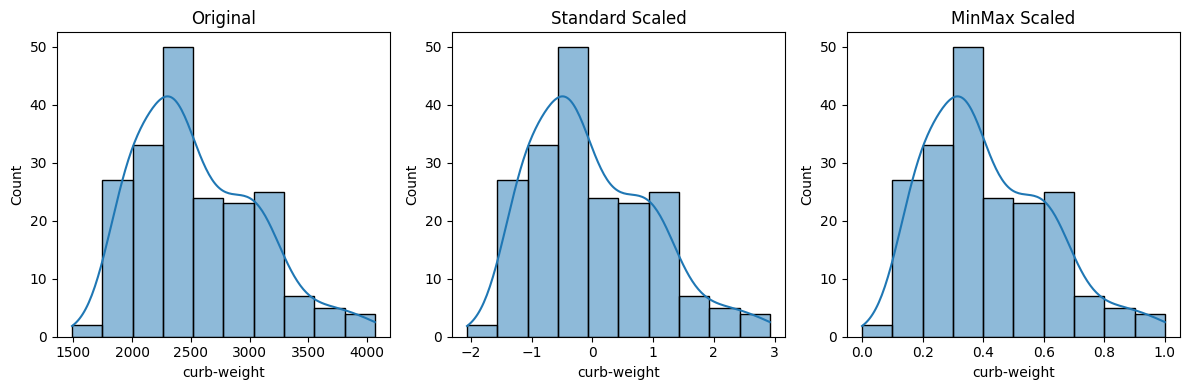

In [24]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.histplot(df["curb-weight"], kde=True)
plt.title("Original")

plt.subplot(1, 3, 2)
sns.histplot(df_standard["curb-weight"], kde=True)
plt.title("Standard Scaled")

plt.subplot(1, 3, 3)
sns.histplot(df_minmax["curb-weight"], kde=True)
plt.title("MinMax Scaled")

plt.tight_layout()
plt.show()

In [25]:
df_standard.to_csv(
    r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-3-Data-Cleaning-and-Preprocessing\automobile_cleaned.csv",
    index=False
)

print("Cleaned dataset saved as automobile_cleaned.csv")

Cleaned dataset saved as automobile_cleaned.csv


In [26]:
print("DATA CLEANING AND PREPROCESSING - SUMMARY")
print("-------------------------------------------")
print("Original rows    :", original_shape[0])
print("Final rows       :", df_standard.shape[0])
print("Original columns :", original_shape[1])
print("Final columns    :", df_standard.shape[1])
print("Missing values   :", df_standard.isnull().sum().sum())
print("Duplicate rows   :", df_standard.duplicated().sum())

DATA CLEANING AND PREPROCESSING - SUMMARY
-------------------------------------------
Original rows    : 205
Final rows       : 200
Original columns : 26
Final columns    : 60
Missing values   : 0
Duplicate rows   : 0
